# Clustering the PCA embeddings

Picking up from the PCA-embeddings notebook. I have, for each of 290 monthly rebalance dates, a per-stock loadings matrix in `embeddings_lib` (one for Q1, one for Q2). Each stock is a row, each column is a PC, and the number of columns varies per window because the MP cutoff picks a different k each time.

This notebook turns those embeddings into cluster labels.

Design choices, locked before I started:

- **K (number of clusters)**: run BOTH K=11 (matches the GICS sector count, so labels can be compared to GICS in the next notebook) and K=k_MP (varying per window).
- **PC scaling**: each PC divided by its in-sample std, within each window. This is "equal-weight per PC" and is the standard Avellaneda preprocessing for distance-based clustering on factor scores.
- **Methods**: kmeans, Ward, average linkage, single linkage. The first two are the workhorses; average and single are included for completeness so I can show in the diagnostic that they chain badly.

Output: four `(rebal_date, ticker)` MultiIndex DataFrames in `clusters_lib`, each with one column per method.


## 1. Setup


In [1]:
import time
import numpy as np
import pandas as pd
import arcticdb as adb
from collections import defaultdict
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
%matplotlib inline

ARCTIC_URI = "lmdb://./database/arctic"
ac = adb.Arctic(ARCTIC_URI)
embeddings_lib = ac["embeddings_lib"]
metadata_lib   = ac["metadata_lib"]

if "clusters_lib" not in ac.list_libraries():
    ac.create_library("clusters_lib")
clusters_lib = ac["clusters_lib"]


## 2. Load the embeddings and the per-window k

The metadata stored with each embedding includes a `per_window_info` list giving k (the MP survivor count) for every rebal date. I pull both Q1 and Q2 and build the k-lookup tables I'll need below.


In [2]:
q1_item = embeddings_lib.read("q1_embeddings")
q2_item = embeddings_lib.read("q2_embeddings")

q1_emb = q1_item.data
q2_emb = q2_item.data

q1_k = {pd.Timestamp(r["rebal_date"]): int(r["k"]) for r in q1_item.metadata["per_window_info"]}
q2_k = {pd.Timestamp(r["rebal_date"]): int(r["k"]) for r in q2_item.metadata["per_window_info"]}

print(f"Q1 embeddings: shape {q1_emb.shape}, "
      f"{q1_emb.index.get_level_values(0).nunique()} rebal dates, "
      f"k range {min(q1_k.values())} to {max(q1_k.values())}")
print(f"Q2 embeddings: shape {q2_emb.shape}, "
      f"{q2_emb.index.get_level_values(0).nunique()} rebal dates, "
      f"k range {min(q2_k.values())} to {max(q2_k.values())}")
q2_emb.head(3)


Q1 embeddings: shape (135321, 20), 290 rebal dates, k range 10 to 20
Q2 embeddings: shape (128131, 20), 290 rebal dates, k range 12 to 20


PC1       PC2       PC3       PC4       PC5       PC6  \
rebal_date ticker                                                               
2001-12-31 AAMRQ   0.017998  0.038958 -0.070936 -0.116985  0.046730 -0.005276   
           AAPL    0.029658 -0.042031  0.019748  0.011212 -0.037656 -0.071355   
           ABI1    0.027392 -0.028905  0.339342  0.005722  0.074799  0.043147   

                        PC7       PC8       PC9      PC10      PC11      PC12  \
rebal_date ticker                                                               
2001-12-31 AAMRQ  -0.024040 -0.023193  0.095849 -0.082971 -0.053066  0.008616   
           AAPL    0.033965 -0.020079  0.041077  0.000235  0.043806 -0.047530   
           ABI1   -0.104626  0.045632 -0.129691  0.133782  0.050253 -0.048008   

                       PC13      PC14      PC15      PC16      PC17  PC18  \
rebal_date ticker                                                           
2001-12-31 AAMRQ  -0.091138  0.059065  0.131440  0.051747  0.089645   NaN   
           AAPL    0.101020 -0.032197 -0.017038 -0.080215 -0.025934   NaN   
           ABI1   -0.069585  0.030515  0.144566 -0.260956  0.002228   NaN   

                   PC19  PC20  
rebal_date ticker              
2001-12-31 AAMRQ    NaN   NaN  
           AAPL     NaN   NaN  
           ABI1     NaN   NaN

## 3. Two helpers: prepare one window, cluster one window

`prepare_window` takes the slice of an embedding for one rebal date, keeps the first k columns (PCs above the MP floor), drops rows with any NaN, and divides each PC by its in-sample std. The PCA already centered the input so I use `with_mean=False`.

The "equal-weight per PC" scaling is the important bit: without it, PC1 has the largest std (since PCA orders by variance) and dominates Euclidean distance. After scaling, each PC contributes equally, so the clustering reflects the *direction* in factor space rather than which factor happens to have the biggest eigenvalue.


In [3]:
def prepare_window(window_df, k):
    """Slice one rebal date's embedding to its top-k PCs (above MP floor),
    drop NaN rows, equal-weight scale each PC. Returns (tickers_list, X)
    or (None, None) if the window is too sparse."""
    sub = window_df.dropna(axis=1, how="all")
    use_cols = sub.columns[:k]
    sub = sub[use_cols].dropna(axis=0, how="any")
    if sub.shape[0] < 2 or sub.shape[1] < 2:
        return None, None
    X = StandardScaler(with_mean=False).fit_transform(sub.values)
    return sub.index.tolist(), X


`cluster_window` is just a switch over the four methods. Notes:

- kmeans uses `n_init=20` to avoid getting stuck in local minima. Random seed is fixed for reproducibility.
- Ward, average, and single linkage all use Euclidean distance in the scaled PC space.


In [4]:
def cluster_window(X, K, method, seed=0):
    """Returns labels in [0..K-1], length n_tickers."""
    if method == "kmeans":
        return KMeans(n_clusters=K, n_init=20, random_state=seed).fit_predict(X)
    if method == "ward":
        return AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
    if method == "average":
        return AgglomerativeClustering(n_clusters=K, linkage="average",
                                        metric="euclidean").fit_predict(X)
    if method == "single":
        return AgglomerativeClustering(n_clusters=K, linkage="single",
                                        metric="euclidean").fit_predict(X)
    raise ValueError(f"unknown method: {method}")


## 4. Master loop: build labels for one (panel, K-scheme)

For each rebal date in a panel, run all four methods at the chosen K and collect the per-stock labels into a long-form DataFrame indexed by `(rebal_date, ticker)`. The result has one column per method.

`K_scheme="K11"` forces K=11 every window. `K_scheme="Kmp"` uses the per-window MP survivor count as K, which varies between roughly 11 and 20.


In [5]:
METHODS = ["kmeans", "ward", "average", "single"]

def build_labels_for(panel_emb, panel_k_lookup, K_scheme):
    rows = []
    skipped = 0
    for date, group in panel_emb.groupby(level=0):
        window = group.droplevel(0)
        k_window = panel_k_lookup.get(date)
        if k_window is None:
            skipped += 1
            continue
        tickers, X = prepare_window(window, k_window)
        if X is None:
            skipped += 1
            continue
        K = 11 if K_scheme == "K11" else k_window
        if K > X.shape[0]:
            skipped += 1
            continue
        labels = {m: cluster_window(X, K, m) for m in METHODS}
        for i, t in enumerate(tickers):
            rows.append({"rebal_date": date, "ticker": t,
                         **{m: int(labels[m][i]) for m in METHODS}})
    if skipped:
        print(f"  skipped {skipped} windows (insufficient data)")
    return pd.DataFrame(rows).set_index(["rebal_date", "ticker"]).sort_index()


## 5. Run all four combinations

Q1 x {K11, Kmp} and Q2 x {K11, Kmp}. Should take roughly a minute total.


In [6]:
results = {}
for panel_name, panel_emb, panel_k in [("q1", q1_emb, q1_k), ("q2", q2_emb, q2_k)]:
    for K_scheme in ("K11", "Kmp"):
        key = f"{panel_name}_labels_{K_scheme}"
        t0 = time.time()
        print(f"\nbuilding {key} ...")
        results[key] = build_labels_for(panel_emb, panel_k, K_scheme)
        print(f"  done in {time.time()-t0:.1f}s  shape={results[key].shape}  "
              f"rebal dates={results[key].index.get_level_values(0).nunique()}")

for k, df in results.items():
    print(f"{k}: {df.shape}  unique labels per method = "
          + ", ".join(f"{m}:{df[m].nunique()}" for m in METHODS))



building q1_labels_K11 ...


  done in 6.3s  shape=(135321, 4)  rebal dates=290

building q1_labels_Kmp ...


  done in 7.6s  shape=(135321, 4)  rebal dates=290

building q2_labels_K11 ...


  done in 8.4s  shape=(128131, 4)  rebal dates=290

building q2_labels_Kmp ...


  done in 7.9s  shape=(128131, 4)  rebal dates=290
q1_labels_K11: (135321, 4)  unique labels per method = kmeans:11, ward:11, average:11, single:11
q1_labels_Kmp: (135321, 4)  unique labels per method = kmeans:20, ward:20, average:20, single:20
q2_labels_K11: (128131, 4)  unique labels per method = kmeans:11, ward:11, average:11, single:11
q2_labels_Kmp: (128131, 4)  unique labels per method = kmeans:20, ward:20, average:20, single:20


## 6. Cluster-size diagnostic: does single linkage chain?

For the most recent rebal date in Q2, plot the cluster-size distribution per method, K=11 on the left and K=Kmp on the right. The expected pattern:

- **kmeans and Ward**: roughly balanced clusters. Biggest cluster maybe 100-200 stocks on a ~500-stock universe.
- **average linkage**: usually one large cluster plus a small tail. This is the start of chaining.
- **single linkage**: textbook chaining. One giant cluster covering almost everything, plus (K-1) singletons.

This is why the next notebook (ARI/NMI evaluation) and the portfolio notebooks downstream only use kmeans and Ward.


diagnostic on rebal date: 2026-01-30



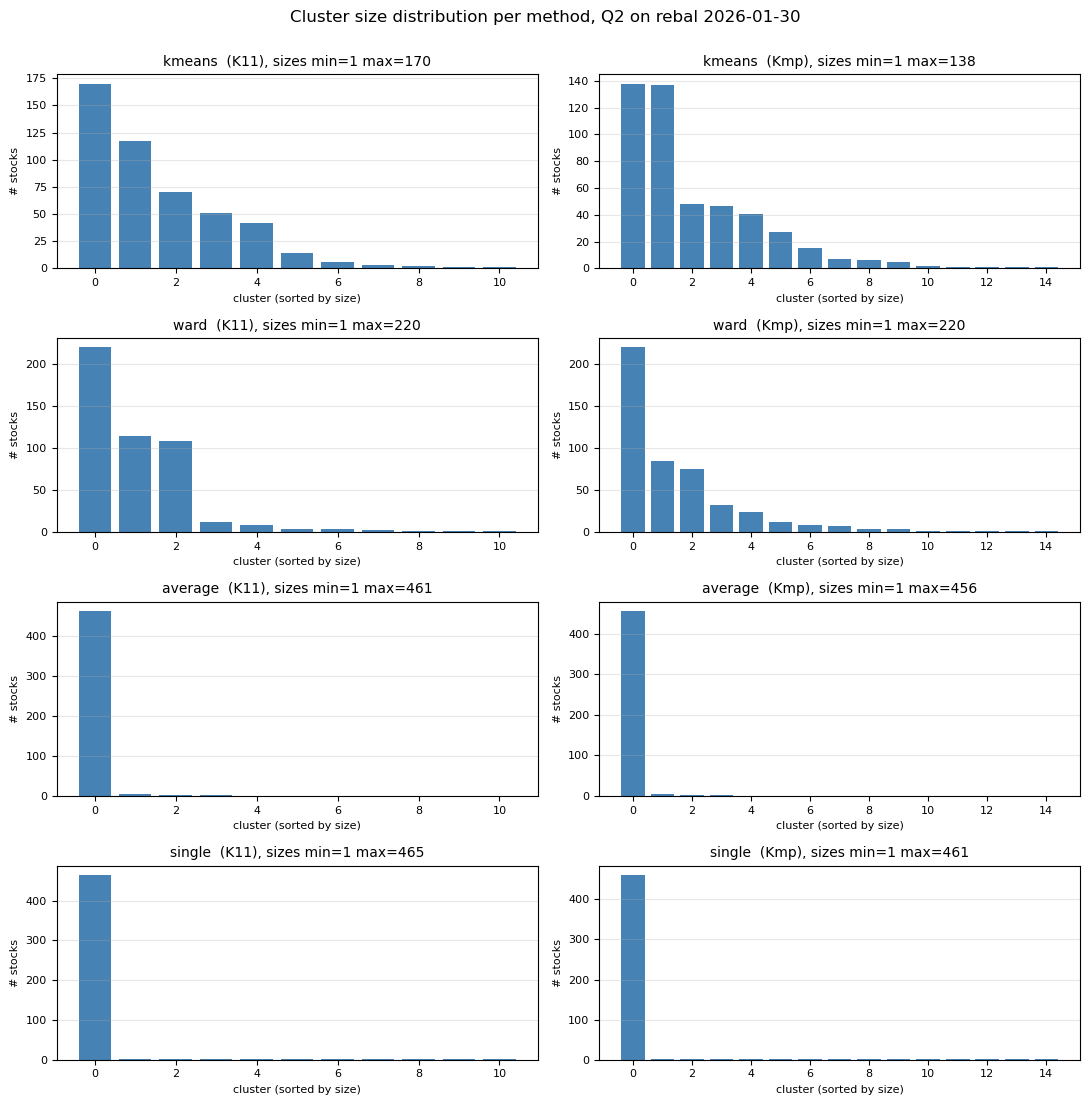

In [7]:
last_date = sorted(set(q2_emb.index.get_level_values(0)))[-1]
print(f"diagnostic on rebal date: {last_date.date()}\n")

fig, axes = plt.subplots(4, 2, figsize=(11, 11), sharey=False)
for col, K_scheme in enumerate(("K11", "Kmp")):
    labels = results[f"q2_labels_{K_scheme}"].xs(last_date, level=0)
    for row, method in enumerate(METHODS):
        ax = axes[row, col]
        counts = labels[method].value_counts().sort_values(ascending=False).values
        ax.bar(range(len(counts)), counts, color="steelblue")
        ax.set_title(f"{method}  ({K_scheme}), sizes min={counts.min()} max={counts.max()}",
                      fontsize=10)
        ax.set_xlabel("cluster (sorted by size)", fontsize=8)
        ax.set_ylabel("# stocks", fontsize=8)
        ax.tick_params(labelsize=8)
        ax.grid(alpha=0.3, axis="y")
fig.suptitle(f"Cluster size distribution per method, Q2 on rebal {last_date.date()}", y=1.00)
fig.tight_layout()
plt.show()


## 7. Save labels to `clusters_lib`

Four symbols total: `q1_labels_K11`, `q1_labels_Kmp`, `q2_labels_K11`, `q2_labels_Kmp`. Each has one column per method (kmeans, ward, average, single). Provenance metadata records the source embedding, scaling rule, K scheme, and method parameters so downstream consumers can read them unambiguously.


In [8]:
for panel_name, panel_emb_meta in [
    ("q1", q1_item.metadata), ("q2", q2_item.metadata)
]:
    for K_scheme in ("K11", "Kmp"):
        key = f"{panel_name}_labels_{K_scheme}"
        df = results[key]
        clusters_lib.write(key, df, metadata={
            "source_embedding": f"{panel_name}_embeddings",
            "source_panel": panel_emb_meta["source_panel"],
            "scaling": "equal-weight per PC within each rebal window",
            "K_scheme": K_scheme,
            "K_value": 11 if K_scheme == "K11" else "per-window MP survivor count",
            "methods": METHODS,
            "kmeans_n_init": 20,
            "kmeans_random_state": 0,
            "agglomerative_metric": "euclidean",
            "n_rebal_dates": int(df.index.get_level_values(0).nunique()),
            "n_rows": int(len(df)),
            "fetched": pd.Timestamp.now(),
        })
        print(f"  persisted {key}: {df.shape}")

print("\nclusters_lib symbols:", clusters_lib.list_symbols())


  persisted q1_labels_K11: (135321, 4)
  persisted q1_labels_Kmp: (135321, 4)
  persisted q2_labels_K11: (128131, 4)
  persisted q2_labels_Kmp: (128131, 4)

clusters_lib symbols: ['q1_labels_Kmp', 'q0direct_labels_K11', 'q0_labels_K11', 'q1_labels_K11', 'q2_labels_K11', 'q2_labels_Kmp']
